# Aligning partially matched, serial, single-cell resolution breast cancer spatial transcriptomics data from Xenium

In this notebook, we take two single cell resolution spatial transcriptomics datasets of serial breast cancer sections profiled by the Xenium technology and align them to each other. See the bioRxiv preprint for more details about this data: https://www.biorxiv.org/content/10.1101/2022.10.06.510405v2 

We will use `STalign` to achieve this alignment. We will first load the relevant code libraries.

For two sets of cells, `STalign.align_cells` is an alternative that runs the main steps of this tutorial in one call; see the last section.

In [1]:
# import dependencies
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch

# make plots bigger
plt.rcParams["figure.figsize"] = (10,8)

In [ ]:
# OPTION A: import STalign after pip or pipenv install
from STalign import STalign

In [2]:
## OPTION B: skip cell if installed STalign with pip or pipenv
import sys
sys.path.append("../../STalign")

## import STalign from upper directory
import STalign

We have already downloaded single cell spatial transcriptomics data from and placed the files in a folder called `xenium_data`: https://www.10xgenomics.com/products/xenium-in-situ/preview-dataset-human-breast

We can read in the cell information for the first dataset using `pandas` as `pd`.

In [3]:
# Single cell data 1
# read in data
fname = '../xenium_data/Xenium_FFPE_Human_Breast_Cancer_Rep1_cells.csv.gz'
df1 = pd.read_csv(fname)
print(df1.head())

   cell_id  x_centroid  y_centroid  transcript_counts  control_probe_counts  \
0        1  377.663005  843.541888                154                     0   
1        2  382.078658  858.944818                 64                     0   
2        3  319.839529  869.196542                 57                     0   
3        4  259.304707  851.797949                120                     0   
4        5  370.576291  865.193024                120                     0   

   control_codeword_counts  total_counts   cell_area  nucleus_area  
0                        0           154  110.361875     45.562656  
1                        0            64   87.919219     24.248906  
2                        0            57   52.561875     23.526406  
3                        0           120   75.230312     35.176719  
4                        0           120  180.218594     34.499375  


For alignment with `STalign`, we only need the cell centroid information. So we can pull out this information. We can further visualize the cell centroids to get a sense of the variation in cell density that we will be relying on for our alignment by plotting using `matplotlib.pyplot` as `plt`. 

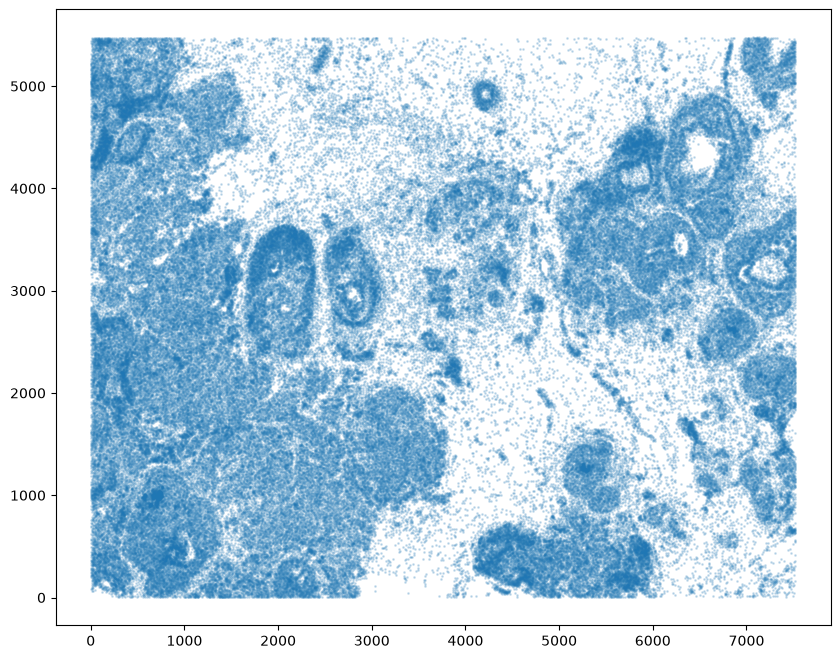

In [4]:
# get cell centroid coordinates
xI = np.array(df1['x_centroid'])
yI = np.array(df1['y_centroid'])

# plot
fig,ax = plt.subplots()
ax.scatter(xI,yI,s=1,alpha=0.2)

We will first use `STalign` to rasterize the single cell centroid positions into an image. Assuming the single-cell centroid coordinates are in microns, we will perform this rasterization at a 30 micron resolution. We can visualize the resulting rasterized image.

Note that points are plotting with the origin at bottom left while images are typically plotted with origin at top left so we've used `invert_yaxis()` to invert the yaxis for visualization consistency. 

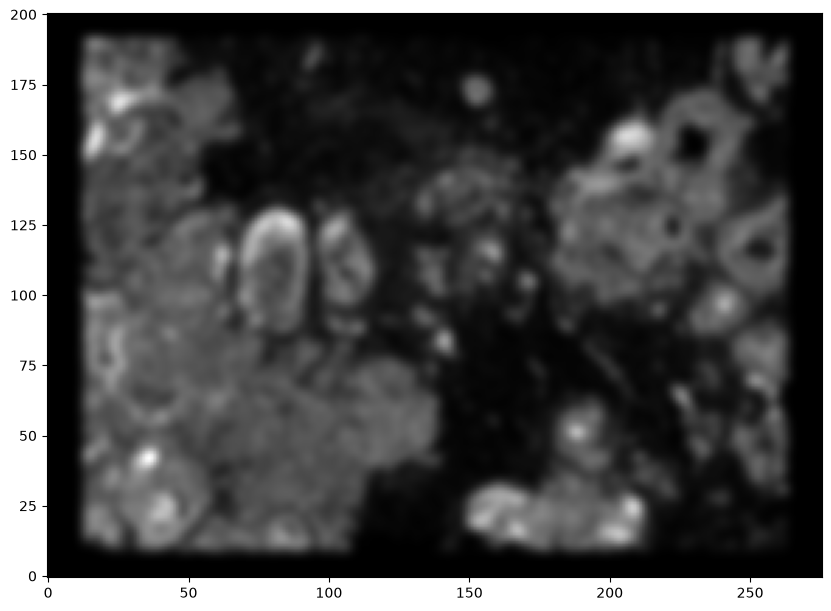

In [5]:
# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I,fig = STalign.rasterize(xI,yI,dx=30)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

Now, we can repeat this for the cell information from the second dataset.

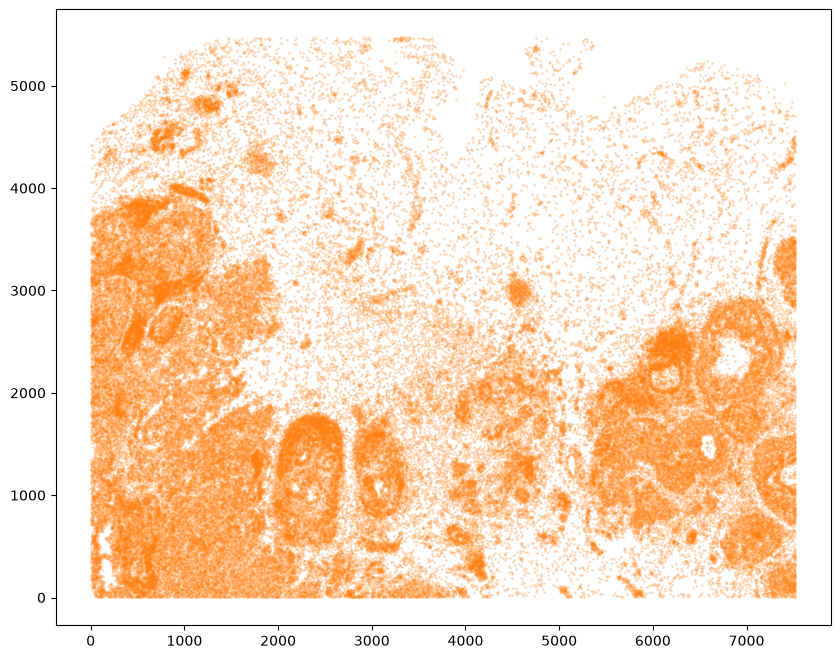

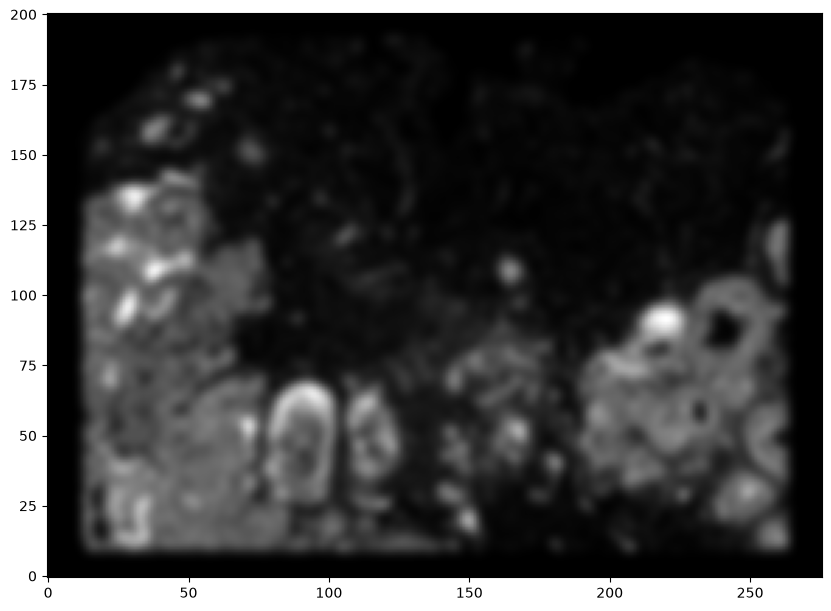

In [6]:
# Single cell data 2
# read in data
fname = '../xenium_data/Xenium_FFPE_Human_Breast_Cancer_Rep2_cells.csv.gz'
df2 = pd.read_csv(fname)

# get cell centroids
xJ = np.array(df2['x_centroid'])
yJ = np.array(df2['y_centroid'])

# plot
fig,ax = plt.subplots()
ax.scatter(xJ,yJ,s=1,alpha=0.2,c='#ff7f0e')

# rasterize and plot
XJ,YJ,J,fig = STalign.rasterize(xJ,yJ,dx=30)
ax = fig.axes[0]
ax.invert_yaxis()

Note that plotting the cell centroid positions from both datasets shows that alignment is still needed.

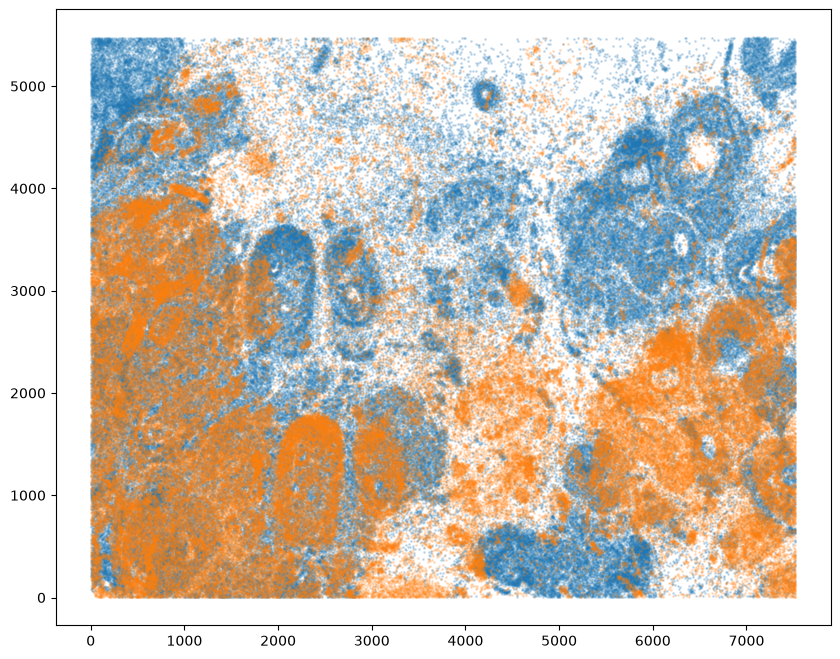

In [7]:
# plot
fig,ax = plt.subplots()
ax.scatter(xI,yI,s=1,alpha=0.2)
ax.scatter(xJ,yJ,s=1,alpha=0.2)

`STalign` relies on an interative gradient descent to align these two images. This can be somewhat slow. So we can manually designate a few landmark points to help initialize the alignment. A `curve_annotator.py` script is provided to assist with this. In order to use the `curve_annotator.py` script, we will need to write out our images as `.npz` files. 

In [8]:
# Optional: write out npz files for landmark point picker
np.savez('../xenium_data/Xenium_Breast_Cancer_Rep1', x=XI,y=YI,I=I)
np.savez('../xenium_data/Xenium_Breast_Cancer_Rep2', x=XJ,y=YJ,I=J)
# outputs Xenium_Breast_Cancer_Rep1.npz and Xenium_Breast_Cancer_Rep2.npz

Given these `.npz` files, we can then run the following code:
    
```
python curve_annotator.py Xenium_Breast_Cancer_Rep1.npz
python curve_annotator.py Xenium_Breast_Cancer_Rep2.npz
```

Which will provide a graphical user interface to selecting landmark points, which will then be saved in `Xenium_Breast_Cancer_Rep1_points.npy` and `Xenium_Breast_Cancer_Rep2_points.npy` respectively. We can then read in these files. 

In [9]:
# read from file
pointsIlist = np.load('../xenium_data/Xenium_Breast_Cancer_Rep1_points.npy', allow_pickle=True).tolist()
print(pointsIlist)
pointsJlist = np.load('../xenium_data/Xenium_Breast_Cancer_Rep2_points.npy', allow_pickle=True).tolist()
print(pointsJlist)

{'0': [(np.float64(2065.0390375683187), np.float64(3096.538441761356))], '1': [(np.float64(6505.52290853606), np.float64(4365.248119180711))], '2': [(np.float64(4226.85355369735), np.float64(4932.828764342001))]}
{'0': [(np.float64(2365.8569852416354), np.float64(1218.8582693193312))], '1': [(np.float64(6839.7279529835705), np.float64(2387.4066564161058))], '2': [(np.float64(4552.711823951313), np.float64(3046.801817706428))]}


Note that these landmark points are read in as lists. We will want to convert them to a simple array for downstream usage. 

In [10]:
# convert to array
pointsI = []
pointsJ = []

# Jean's note: a bit odd to me that the points are stored as y,x
## instead of x,y but all downstream code uses this orientation
for i in pointsIlist.keys():
    pointsI.append([pointsIlist[i][0][1], pointsIlist[i][0][0]])
for i in pointsJlist.keys():
    pointsJ.append([pointsJlist[i][0][1], pointsJlist[i][0][0]])
    
pointsI = np.array(pointsI)
pointsJ = np.array(pointsJ)

In [11]:
# now arrays
print(pointsI)
print(pointsJ)

[[3096.53844176 2065.03903757]
 [4365.24811918 6505.52290854]
 [4932.82876434 4226.8535537 ]]
[[1218.85826932 2365.85698524]
 [2387.40665642 6839.72795298]
 [3046.80181771 4552.71182395]]


Alternatively, you can also just manually create an array of points.

But it will be good to double check that your landmark points look sensible by plotting them along with the rasterized image we created.

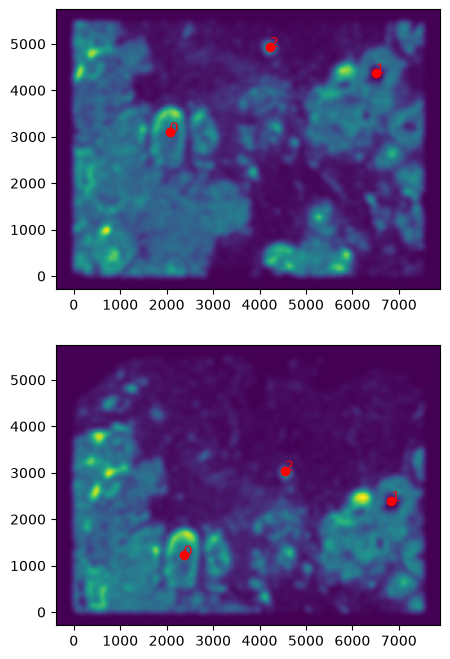

In [12]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(2,1)
ax[0].imshow((I.transpose(1,2,0).squeeze()), extent=extentI) # just want 201x276 matrix
ax[1].imshow((J.transpose(1,2,0).squeeze()), extent=extentJ) # just want 201x276 matrix
# with points
ax[0].scatter(pointsI[:,1], pointsI[:,0], c='red')
ax[1].scatter(pointsJ[:,1], pointsJ[:,0], c='red')
for i in range(pointsI.shape[0]):
    ax[0].text(pointsI[i,1],pointsI[i,0],f'{i}', c='red')
    ax[1].text(pointsJ[i,1],pointsJ[i,0],f'{i}', c='red')
ax[0].invert_yaxis()
ax[1].invert_yaxis()

We can now initialize a simple affine alignment from the landmark points. 

In [13]:
# set device for building tensors
if torch.cuda.is_available():
    torch.set_default_device('cuda:0')
else:
    torch.set_default_device('cpu')

In [14]:
# compute initial affine transformation from points
L,T = STalign.L_T_from_points(pointsI, pointsJ)
A = STalign.to_A(torch.tensor(L),torch.tensor(T))

We can show the results of the simple affine transformation.

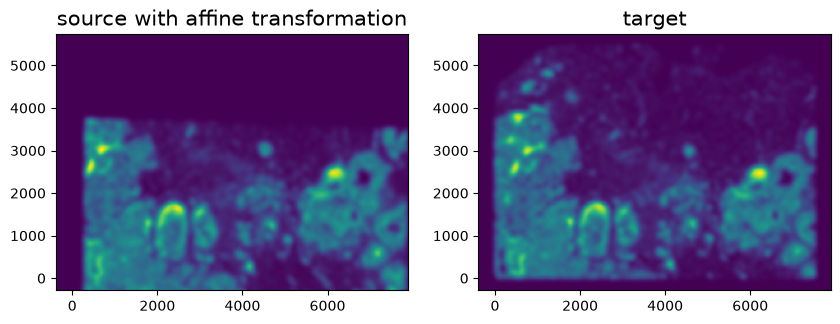

In [15]:
# compute initial affine transformation from points
AI = STalign.transform_image_source_with_A(A, [YI,XI], I, [YJ,XJ])

#switch tensor from cuda to cpu for plotting with numpy
if AI.is_cuda:
    AI = AI.cpu()

fig,ax = plt.subplots(1,2)
ax[0].imshow((AI.permute(1,2,0).squeeze()), extent=extentJ)
ax[1].imshow((J.transpose(1,2,0).squeeze()), extent=extentJ)

ax[0].set_title('source with affine transformation', fontsize=15)
ax[1].set_title('target', fontsize=15)

ax[0].invert_yaxis()
ax[1].invert_yaxis()

Depending on distortions in the tissue sample (as well as the accuracy of your landmark points), a simple affine alignment may not be sufficient to align the two single-cell spatial transcriptomics datasets. So we will need to perform non-linear local alignments via LDDMM. 

There are many parameters that can be tuned for performing this alignment. 

CPU times: user 3.84 s, sys: 124 ms, total: 3.96 s
Wall time: 977 ms


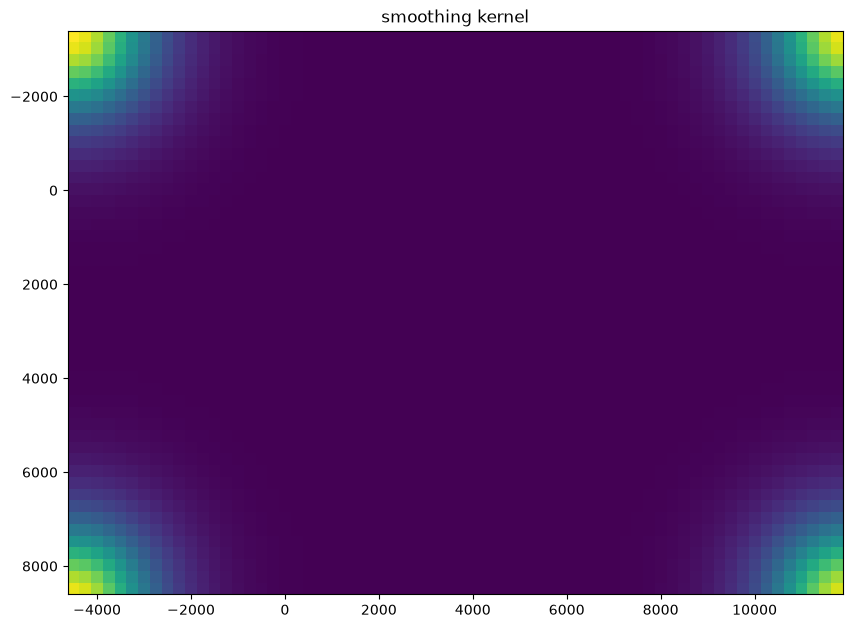

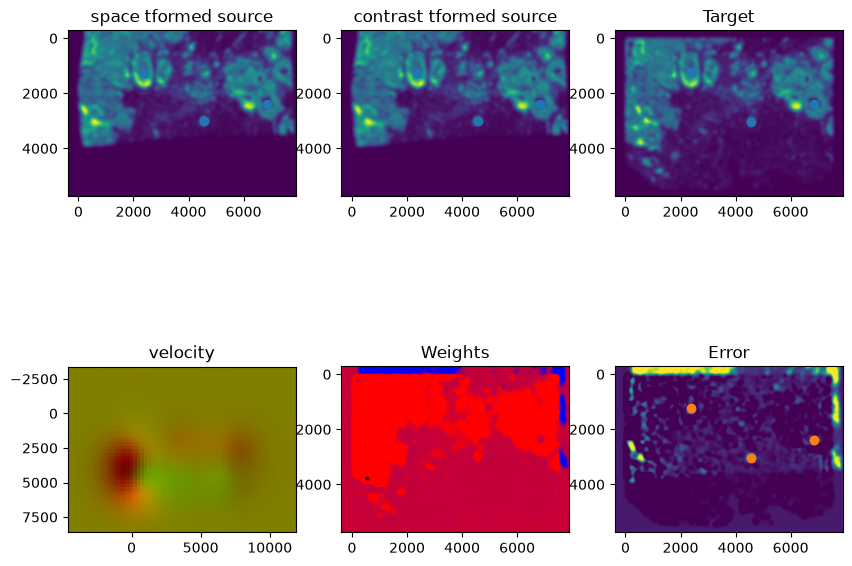

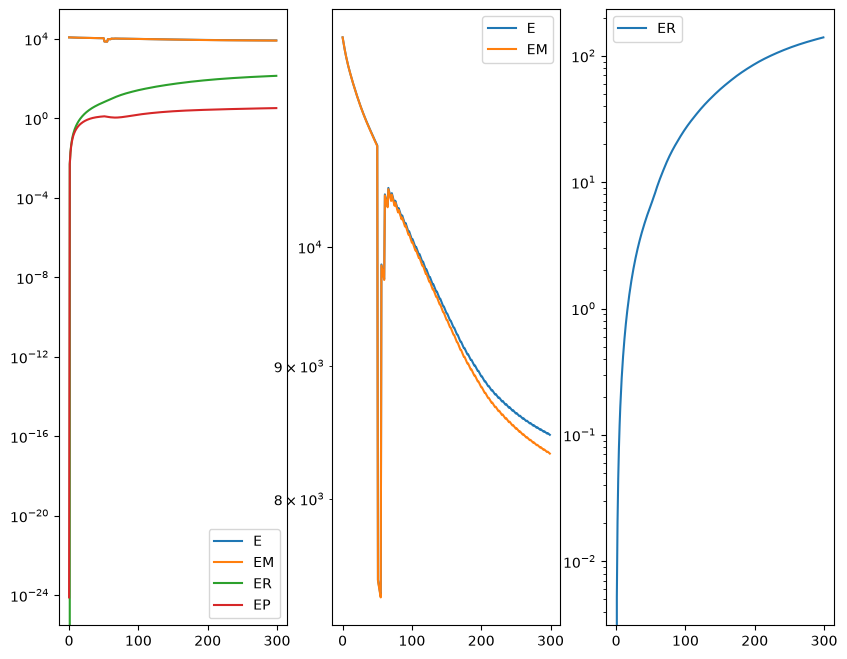

In [16]:
%%time

# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {'L':L,'T':T,
          'niter':300,
          'pointsI':pointsI,
          'pointsJ':pointsJ,
          'device':device,
          'sigmaM':1.5,
          'sigmaB':1.0,
          'sigmaA':1.1,
          'epV': 100
          }

out = STalign.LDDMM([YI,XI],I,[YJ,XJ],J,**params)

In [17]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']

Plots generated throughout the alignment can be used to give you a sense of whether the parameter choices are appropriate and whether your alignment is converging on a solution.

We can also evaluate the resulting alignment by applying the transformation to visualize how our source and target images were deformed to achieve the alignment. 

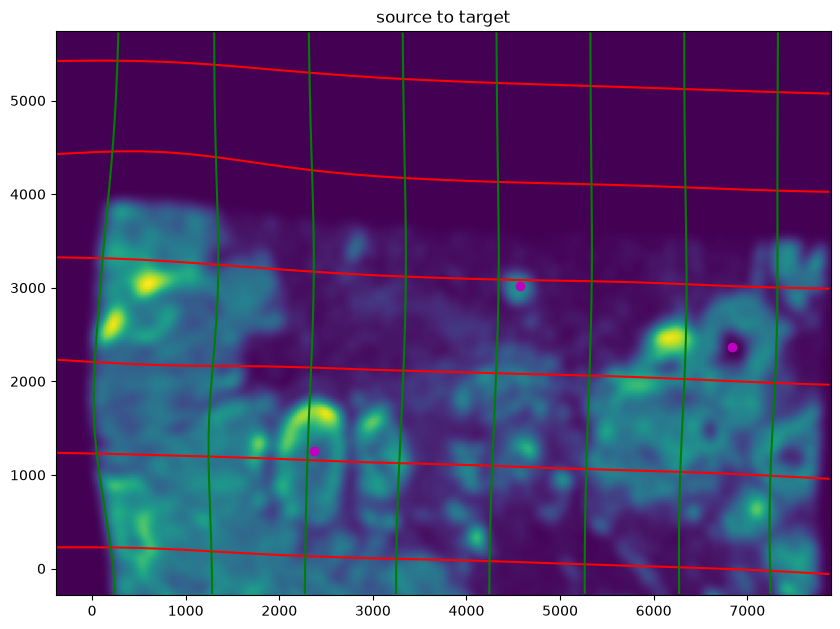

In [18]:
# apply transform
phii = STalign.build_transform(xv,v,A,XJ=[YJ,XJ],direction='b')
phiI = STalign.transform_image_source_to_target(xv,v,A,[YI,XI],I,[YJ,XJ])
phipointsI = STalign.transform_points_source_to_target(xv,v,A,pointsI)

#switch tensor from cuda to cpu for plotting with numpy
if phii.is_cuda:
    phii = phii.cpu()
if phiI.is_cuda:
    phiI = phiI.cpu()
if phipointsI.is_cuda:
    phipointsI = phipointsI.cpu()

# plot with grids
fig,ax = plt.subplots()
levels = np.arange(-100000,100000,1000)
ax.contour(XJ,YJ,phii[...,0],colors='r',linestyles='-',levels=levels)
ax.contour(XJ,YJ,phii[...,1],colors='g',linestyles='-',levels=levels)
ax.set_aspect('equal')
ax.set_title('source to target')
ax.imshow(phiI.permute(1,2,0)/torch.max(phiI),extent=extentJ)
ax.scatter(phipointsI[:,1].detach(),phipointsI[:,0].detach(),c="m")
ax.invert_yaxis()

Note that because of our use of LDDMM, the resulting transformation is invertible.

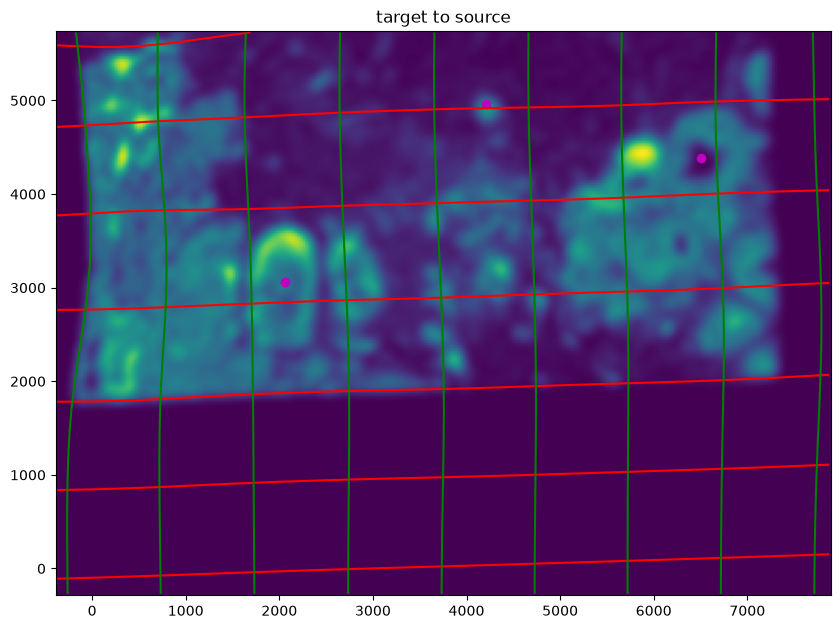

In [19]:
# transform is invertible
phi = STalign.build_transform(xv,v,A,XJ=[YI,XI],direction='f')
phiiJ = STalign.transform_image_target_to_source(xv,v,A,[YJ,XJ],J,[YI,XI])
phiipointsJ = STalign.transform_points_target_to_source(xv,v,A,pointsJ)

#switch tensor from cuda to cpu for plotting with numpy
if phi.is_cuda:
    phi = phi.cpu()
if phiiJ.is_cuda:
    phiiJ = phiiJ.cpu()
if phiipointsJ.is_cuda:
    phiipointsJ = phiipointsJ.cpu()

# plot with grids
fig,ax = plt.subplots()
levels = np.arange(-100000,100000,1000)
ax.contour(XI,YI,phi[...,0],colors='r',linestyles='-',levels=levels)
ax.contour(XI,YI,phi[...,1],colors='g',linestyles='-',levels=levels)
ax.set_aspect('equal')
ax.set_title('target to source')
ax.imshow(phiiJ.permute(1,2,0)/torch.max(phiiJ),extent=extentI)
ax.scatter(phiipointsJ[:,1].detach(),phiipointsJ[:,0].detach(),c="m")
ax.invert_yaxis()

Finally, we can apply our transform to the original sets of single cell centroid positions to achieve their new aligned positions.

In [20]:
# apply transform to original points of target to source
tpointsJ = STalign.transform_points_target_to_source(xv,v,A, np.stack([yJ, xJ], 1))

#switch tensor from cuda to cpu for plotting with numpy
if tpointsJ.is_cuda:
    tpointsJ = tpointsJ.cpu()

And we can visualize the results.

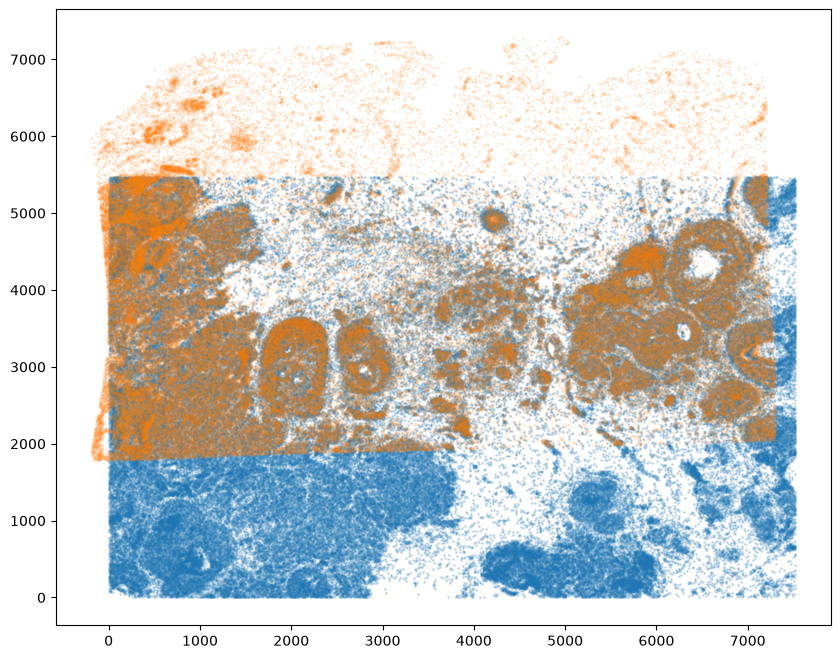

In [21]:
# plot results
fig,ax = plt.subplots()
ax.scatter(xI,yI,s=1,alpha=0.2) 
ax.scatter(tpointsJ[:,1],tpointsJ[:,0],s=1,alpha=0.1) # also needs to plot as y,x not x,y

And save the new aligned positions by appending to our original data using `numpy` with `np.hstack`

In [22]:
# save results: the cells of Rep2 (the target) with their positions in the coordinates of Rep1 (the source)
# tpointsJ holds rows (y, x)
results = df2.copy()
results['aligned_x'] = tpointsJ[:, 1].numpy()
results['aligned_y'] = tpointsJ[:, 0].numpy()
results.head()

,cell_id,x_centroid,y_centroid,transcript_counts,control_probe_counts,control_codeword_counts,total_counts,cell_area,nucleus_area,aligned_x,aligned_y
0,1,479.934467,869.789633,207,0,0,207,166.310469,44.343438,335.130524,2642.622382
1,2,481.256989,851.689365,147,0,0,147,218.420781,37.253906,334.130221,2624.393959
2,3,490.647247,855.816202,165,0,0,165,110.723125,42.717813,342.644355,2628.810207
3,4,491.177719,866.842908,186,0,0,186,181.482969,63.354219,344.384959,2639.949589
4,5,492.839691,842.511191,82,0,0,82,152.989375,17.204531,342.966406,2615.445346


We will finally create a compressed `.csv.gz` file to create `Xenium_Breast_Cancer_Rep2_STalign_to_Rep1.csv.gz`

In [23]:
results.to_csv('../xenium_data/Xenium_Breast_Cancer_Rep2_STalign_to_Rep1.csv.gz', index=False, compression='gzip')

Note that the learned transform can be applied from source to target or target to source.

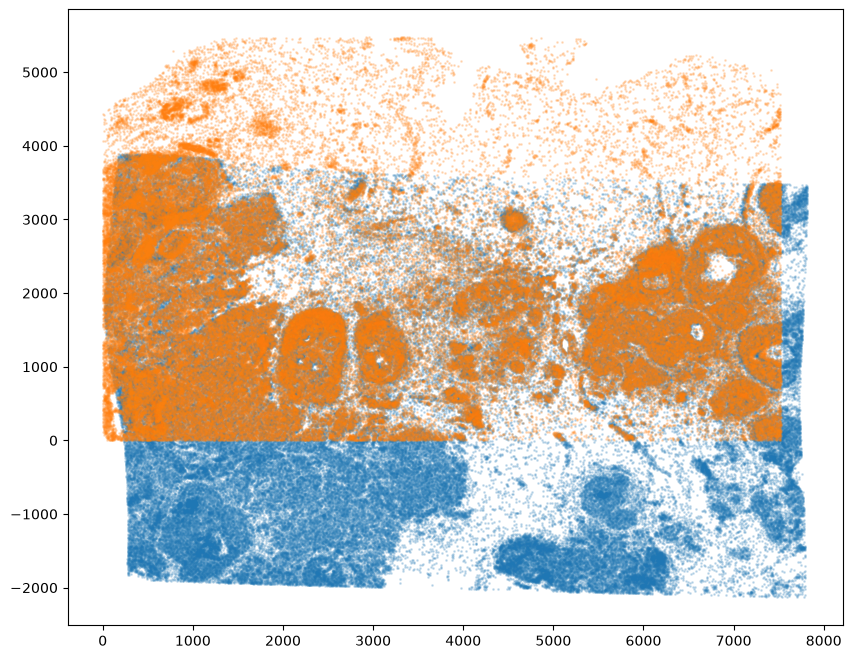

In [24]:
# apply transform to original points of source to target
tpointsI = STalign.transform_points_source_to_target(xv,v,A, np.stack([yI, xI], 1))

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()
    
# plot results
fig,ax = plt.subplots() 
ax.scatter(tpointsI[:,1],tpointsI[:,0],s=1,alpha=0.2) # also needs to plot as y,x not x,y
ax.scatter(xJ,yJ,s=1,alpha=0.2)

We can also use the matching weights to focus on the tissue region that is overlapping given the partially matching nature of this alignment.

In [25]:
# get the weights
WM = out['WM']
# compute weight values for transformed source points from target image pixel locations and weight 2D array (matching)
testM = STalign.interp([YJ,XJ],WM[None].float(),tpointsI[None].permute(-1,0,1).float())

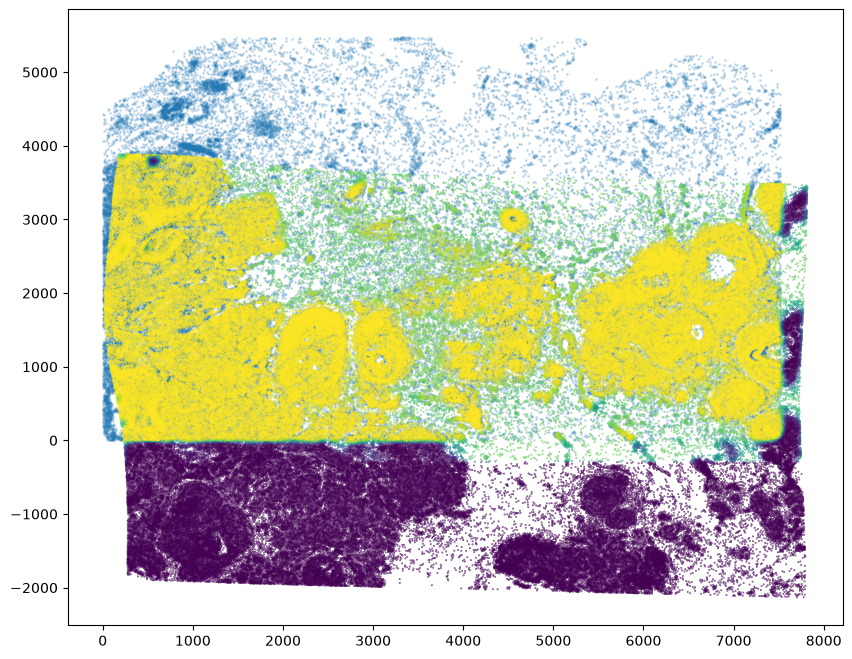

In [26]:
# note some cells were allocated into the artifact component (not matching and so not included, may need to tune sigmaA)
fig,ax = plt.subplots()
ax.scatter(xJ,yJ,s=1,alpha=0.2)
ax.scatter(tpointsI[:,1],tpointsI[:,0],c=testM[0,0],s=0.1,vmin=0,vmax=1, label='WM values')

(array([62208.,   930.,   547.,   375.,   277.,   239.,   235.,   213.,
          185.,   197.,   239.,   255.,   356.,   325.,   694.,  5249.,
         2486.,  2635.,  3146., 86991.]),
 array([0.        , 0.04999994, 0.09999988, 0.14999983, 0.19999976,
        0.2499997 , 0.29999965, 0.34999958, 0.39999953, 0.44999948,
        0.4999994 , 0.54999936, 0.59999931, 0.64999926, 0.69999915,
        0.74999911, 0.79999906, 0.84999901, 0.89999896, 0.94999886,
        0.99999881]),
 <BarContainer object of 20 artists>)

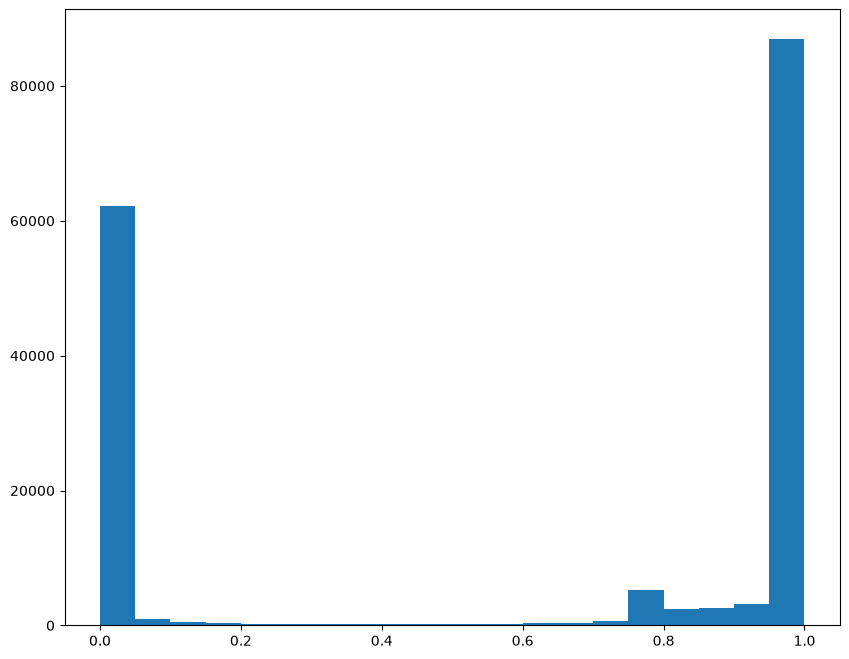

In [27]:
# visualize the distribution to identify reasonable cutoff
fig,ax = plt.subplots()
ax.hist(testM[0,0], bins = 20)

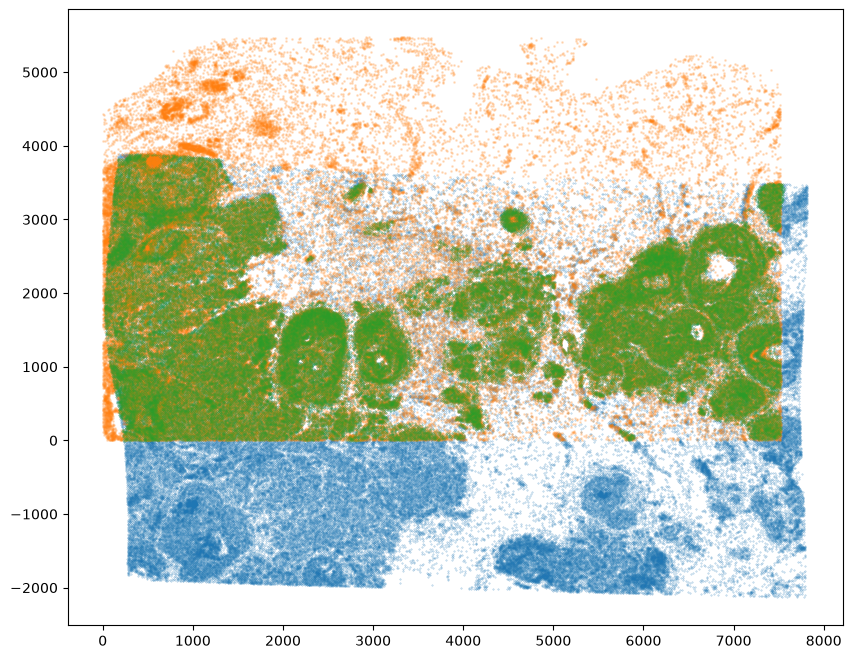

In [28]:
# set a threshold value
WMthresh = 0.9

# plot just the cells that pass filter (overlapping cells)
filtered = testM[0,0] > WMthresh
tpointsI_filtered = tpointsI[filtered,]

fig,ax = plt.subplots()
ax.scatter(tpointsI[:,1],tpointsI[:,0],s=0.1,alpha=0.5, label='original')
ax.scatter(xJ,yJ,s=1,alpha=0.2)
ax.scatter(tpointsI_filtered[:,1],tpointsI_filtered[:,0],s=0.1,alpha=0.5, label='filtered')

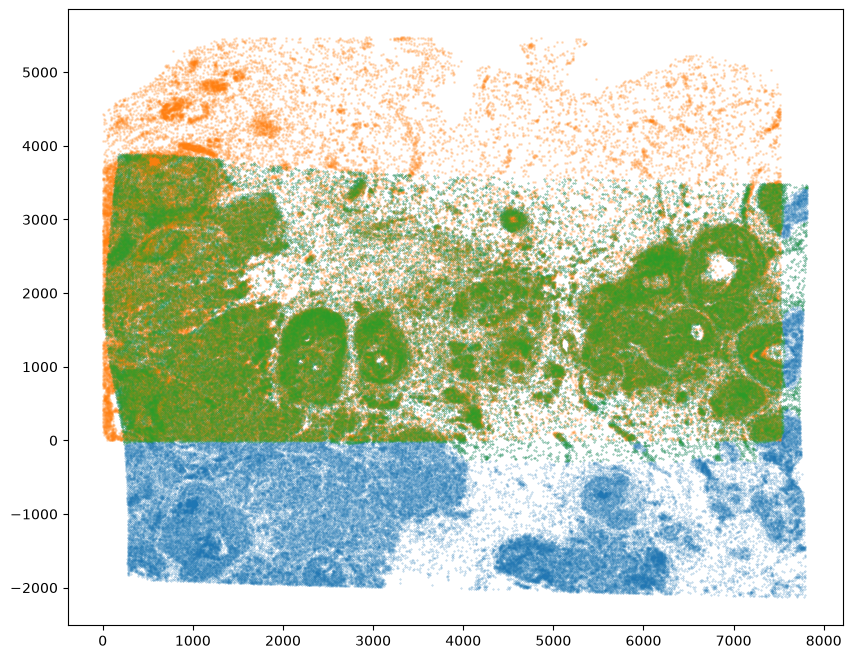

In [29]:
# choose less stringent threshold value
WMthresh = 0.5

# plot just the cells that pass filter (overlapping cells)
filtered = testM[0,0] > WMthresh
tpointsI_filtered = tpointsI[filtered,]

fig,ax = plt.subplots()
ax.scatter(tpointsI[:,1],tpointsI[:,0],s=0.1,alpha=0.5, label='original')
ax.scatter(xJ,yJ,s=1,alpha=0.2)
ax.scatter(tpointsI_filtered[:,1],tpointsI_filtered[:,0],s=0.1,alpha=0.5, label='filtered')

In this manner, we can restrict to just the cells that are matching for downstream analysis. 

## Alternative: `align_cells`

`STalign.align_cells` runs the steps above in one call. It rasterizes both sets of cells at 15 µm with a Gaussian kernel of 30 µm standard deviation, and runs `LDDMM` coarse to fine (500 iterations on 60 µm pixels, then 500 on 30 µm), with the step sizes and the regularization chosen from the images. It chooses these settings for you: the walkthrough above shows what each of them does, and `align_cells` accepts them as arguments. In our tests on simulated deformations of real cell sets, its error was less than half that of `LDDMM` on a single raster. It returns the same output as `LDDMM`, so the transform functions work on it as above.

By default, `align_cells` uses a mixture model (`mixture='em'`) that gives a low weight to parts of the target that look like background where the source has tissue, which helps when the target section lacks tissue that the source has. These serial sections only partly overlap, the case the mixture model is meant for. For complete sections, also try `mixture=None`, which turns it off: in our tests the mixture model made the alignment of some complete sections with uneven cell density, and of some serial sections, worse.

CPU times: user 10.3 s, sys: 429 ms, total: 10.7 s
Wall time: 5.15 s


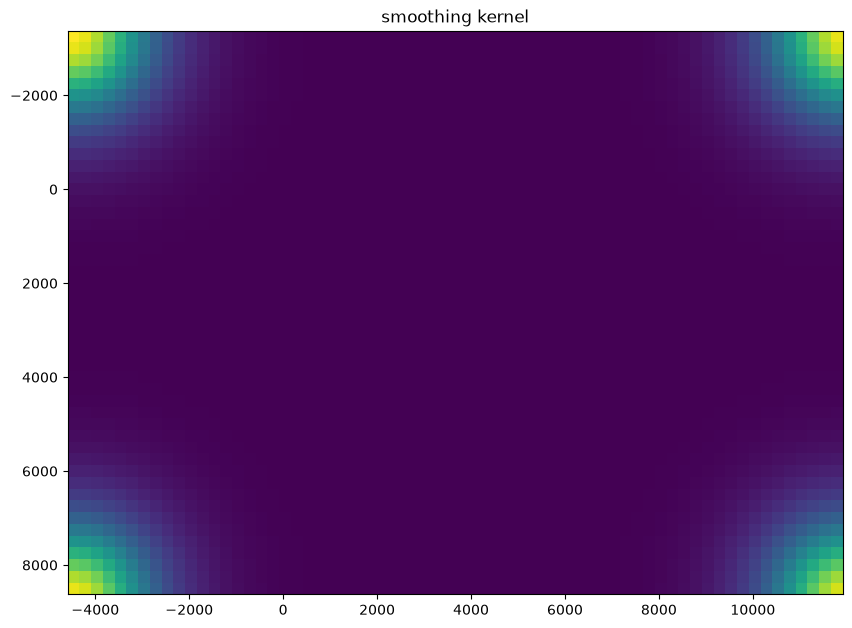

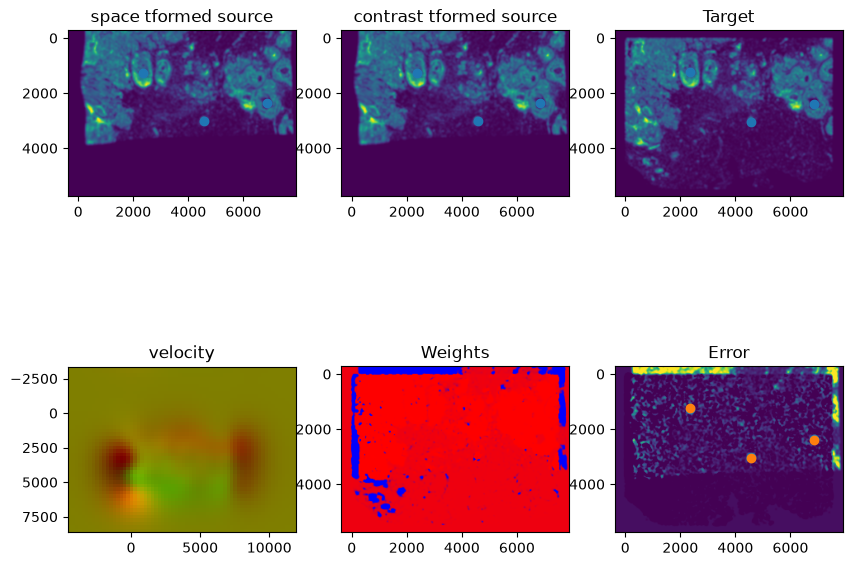

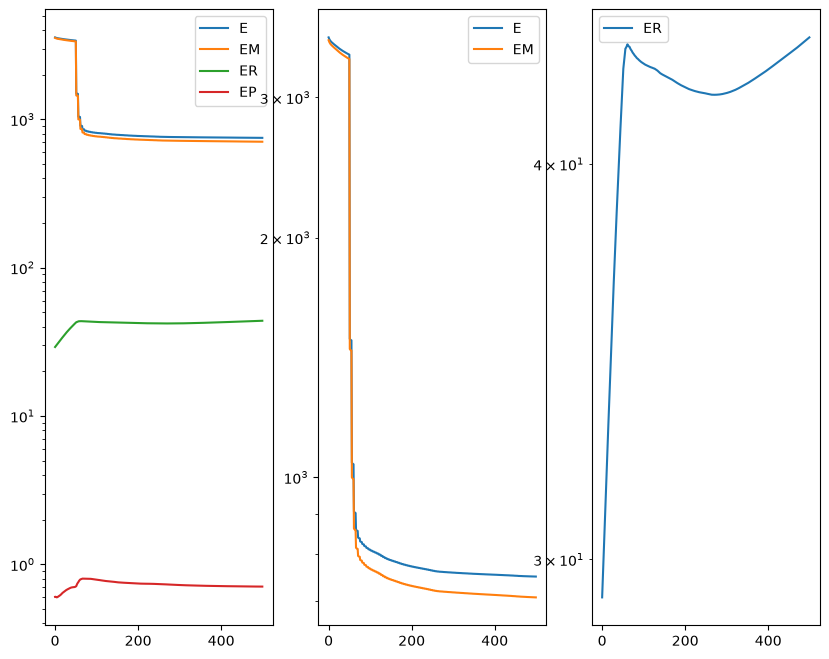

In [30]:
%%time
# align the cells, starting from the affine transformation of the landmark points, and with the landmarks
out_cells = STalign.align_cells(xI, yI, xJ, yJ, L=L, T=T, pointsI=pointsI, pointsJ=pointsJ, device=device)

In [31]:
# apply transform to original points of source to target
tpointsI_cells = STalign.transform_points_source_to_target(out_cells['xv'],out_cells['v'],out_cells['A'], np.stack([yI, xI], 1))

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI_cells.is_cuda:
    tpointsI_cells = tpointsI_cells.cpu()

We can compare the result with that of the step by step alignment above.

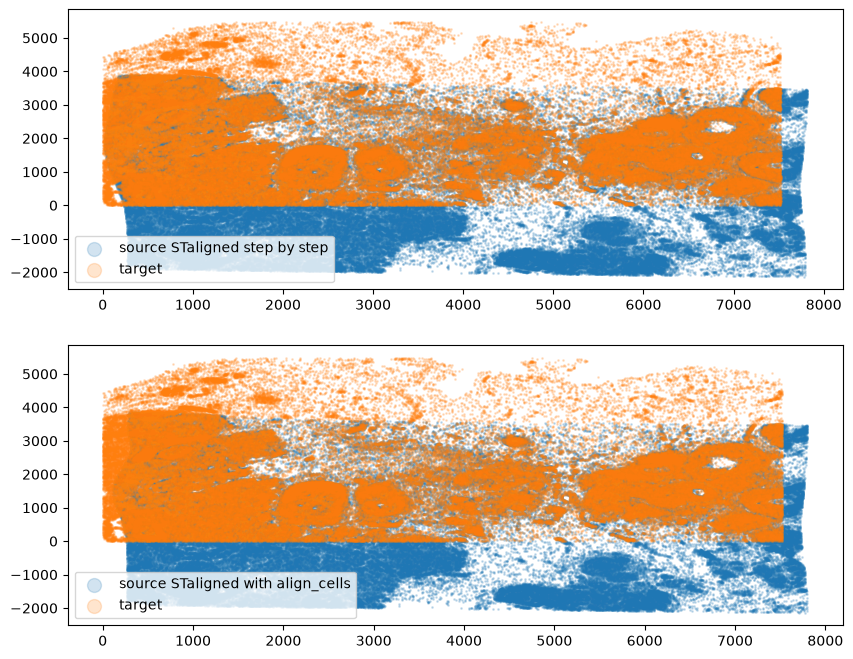

In [32]:
fig,ax = plt.subplots(2,1)
ax[0].scatter(tpointsI[:,1],tpointsI[:,0],s=1,alpha=0.2, label='source STaligned step by step')
ax[0].scatter(xJ,yJ,s=1,alpha=0.2, label='target')
ax[1].scatter(tpointsI_cells[:,1],tpointsI_cells[:,0],s=1,alpha=0.2, label='source STaligned with align_cells')
ax[1].scatter(xJ,yJ,s=1,alpha=0.2, label='target')
ax[0].legend(markerscale = 10, loc = 'lower left')
ax[1].legend(markerscale = 10, loc = 'lower left')

In [33]:
# distance between the two aligned positions of each cell
d = np.sqrt(np.sum((tpointsI_cells.numpy() - tpointsI.numpy())**2, axis=1))
print('distance between the two results: mean {:.1f}, median {:.1f}, 95th percentile {:.1f}'.format(
    np.mean(d), np.median(d), np.percentile(d, 95)))

distance between the two results: mean 28.7, median 14.1, 95th percentile 131.2


The two alignments are close: half of the cells are placed within about 15 µm of each other, half a pixel of the 30 µm images above.